In [1]:
import os
import glob
import json

os.environ['YOLO_VERBOSE'] = 'False'

import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline

In [19]:
RESULTS_PTH = "../results/cam3_revB_batch1_7_margin_15_yolov8n_bg_wb_alif_clahe_box_01_dfl_01_2nd"
WEIGHTS_PTH = os.path.join(RESULTS_PTH, "weights/best.pt")

BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15_wb_alif_clahe"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")

VAL_IMGS_PTH = os.path.join(BASE_PTH, "images/val")
HOLDOUT_IMGS_PTH = os.path.join(BASE_PTH, "images/holdout")

In [20]:
CONF_TH = 0.0
IOU_TH = 0.5

In [21]:
def print_metrics(metrics, conf_th=0, draw=True):
    data = [
        {
            "task": "box",
            "F1": metrics.box.f1[0],
            "P": metrics.box.p[0],
            "R": metrics.box.r[0],
            "MAP@50": metrics.box.map50,
        },
        {
            "task": "pose",
            "F1": metrics.pose.f1[0],
            "P": metrics.pose.p[0],
            "R": metrics.pose.r[0],
            "MAP@50": metrics.pose.map50,
        }
    ]
    print(pd.DataFrame(data))

    if not draw:
        return
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    x = np.linspace(conf_th, 1, num=len(metrics.box.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.box.f1_curve[0], label="F1")
    plt.plot(x, metrics.box.r_curve[0], label="R")
    plt.plot(x, metrics.box.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("BOX")

    plt.subplot(1, 2, 2)
    x = np.linspace(conf_th, 1, num=len(metrics.pose.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.pose.f1_curve[0], label="F1")
    plt.plot(x, metrics.pose.r_curve[0], label="R")
    plt.plot(x, metrics.pose.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("POSE");

## Default Validation

### Hold-out set

   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.943
1  pose 0.928 0.935 0.921   0.962


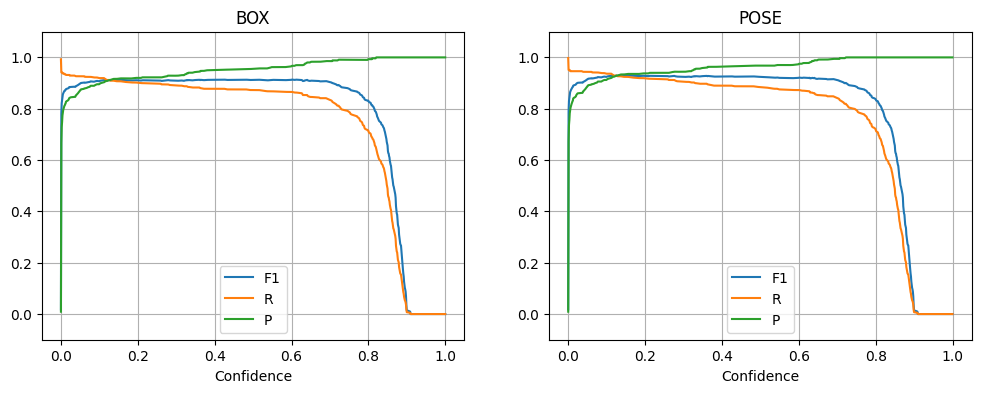

In [22]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=HOLDOUT_PTH,
    task="pose",
    device=[0],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

## CONF TH

In [23]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.1, 0.41, 0.05):
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.1 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.950
1  pose 0.928 0.935 0.921   0.962

0.15000000000000002 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.945
1  pose 0.930 0.936 0.924   0.957

0.20000000000000004 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.942
1  pose 0.927 0.938 0.917   0.953

0.25000000000000006 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.941
1  pose 0.927 0.940 0.914   0.952

0.30000000000000004 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.938
1  pose 0.926 0.963 0.891   0.948

0.3500000000000001 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.935
1  pose 0.928 0.961 0.897   0.945

0.40000000000000013 :
   task    F1     P     R  MAP@50
0   box 0.913 0.952 0.878   0.933
1  pose 0.926 0.966 0.890   0.942



In [24]:
TUNED_CONF_TH = 0.20

## IOU THRESHOLD

In [25]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.55, 0.65]:
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.942
1  pose 0.927 0.938 0.917   0.953

0.5 :
   task    F1     P     R  MAP@50
0   box 0.912 0.952 0.875   0.942
1  pose 0.927 0.938 0.917   0.953

0.55 :
   task    F1     P     R  MAP@50
0   box 0.913 0.954 0.875   0.941
1  pose 0.925 0.966 0.888   0.953

0.65 :
   task    F1     P     R  MAP@50
0   box 0.913 0.957 0.873   0.941
1  pose 0.925 0.965 0.888   0.953



In [26]:
TUNED_IOU_TH = 0.5

In [27]:
with open(os.path.join(RESULTS_PTH, "inference_params.json"), "w") as f:
    json.dump({
        "conf_th": TUNED_CONF_TH,
        "iou_th": TUNED_IOU_TH,
    }, f, indent=4)

## Visuzlization

In [28]:
model = YOLO(WEIGHTS_PTH)

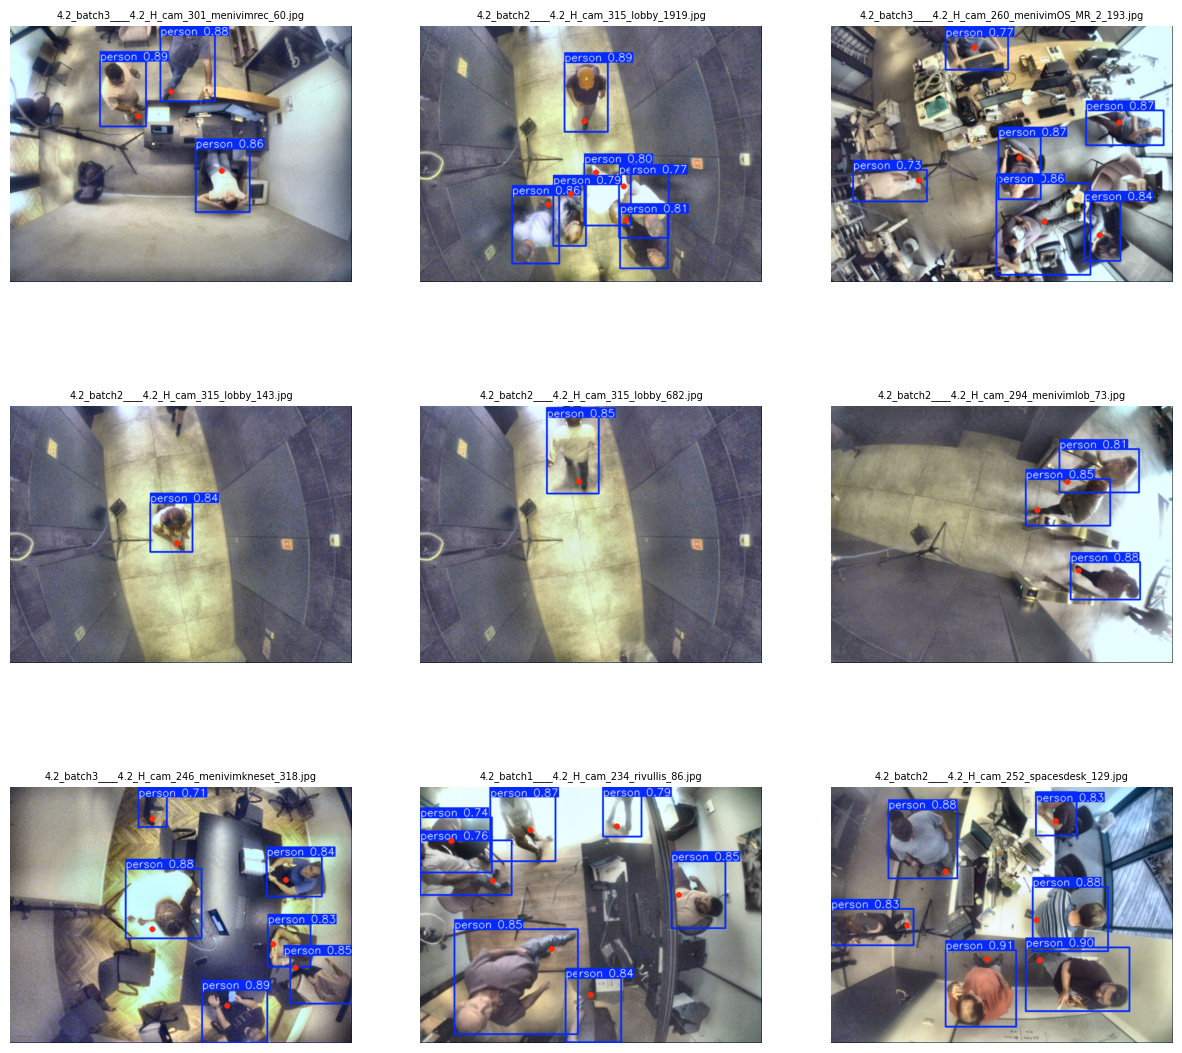

In [29]:
img_pths = glob.glob(os.path.join(VAL_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)

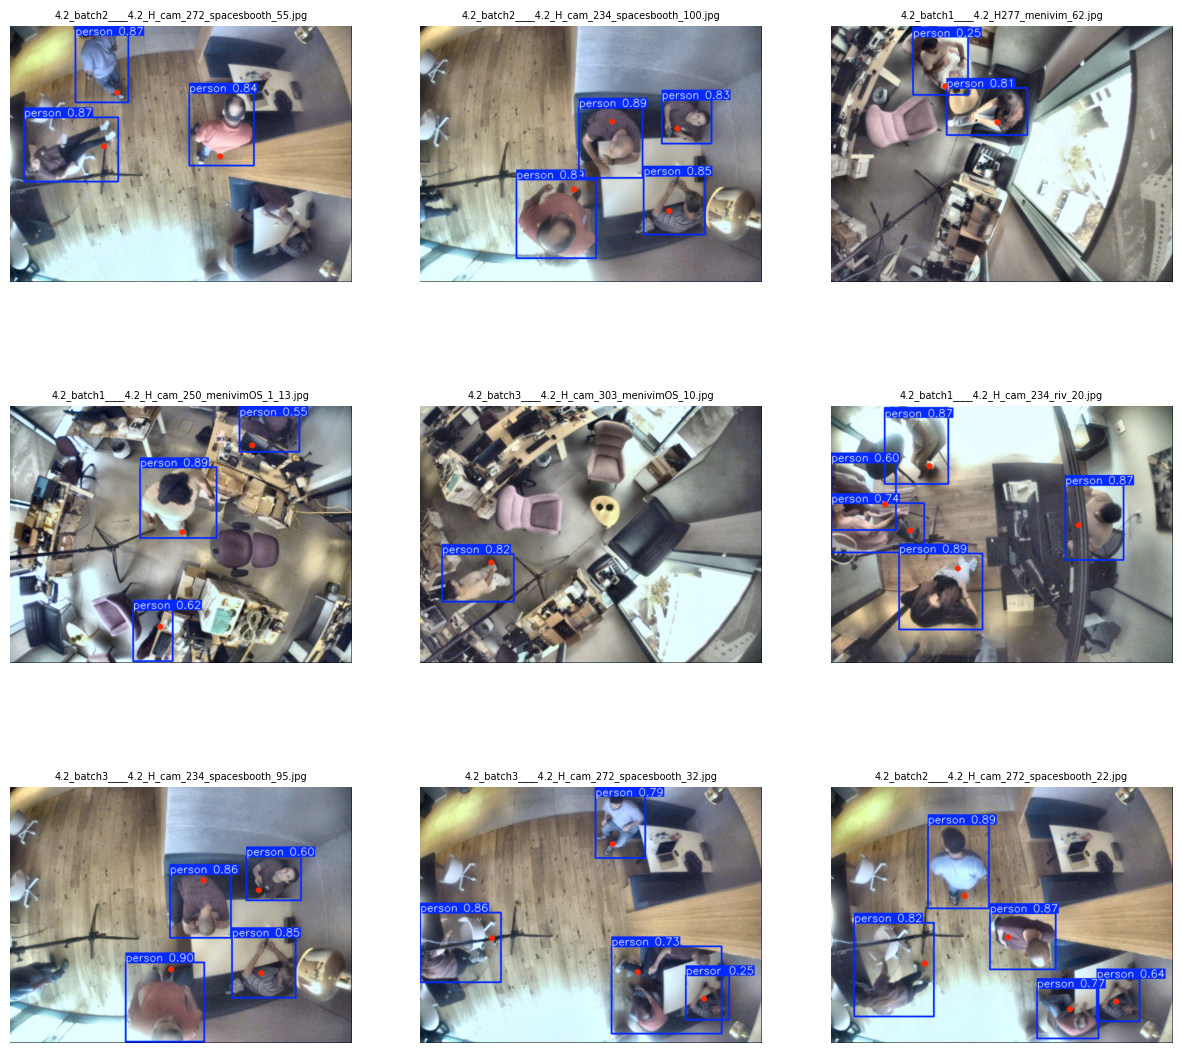

In [30]:
img_pths = glob.glob(os.path.join(HOLDOUT_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)